<a href="https://colab.research.google.com/github/aruzhan2345/Product-Segmentation-using-Clustering-and-PCA/blob/main/BDA_2407_Lab4_Aruzhan_Alimkhan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 4: Product Segmentation using Clustering and PCA
Aruzhan Alimkhan  BDA-2407

Goal: group real menu products by their nutritional characteristics without using existing category labels.



## 1. Dataset
I use Nutrition Facts for McDonald's Menu from [Kaggle](https://www.kaggle.com/datasets/mcdonalds/nutrition-facts) [1]. The dataset description states that menu items and nutrition facts were scraped from McDonald's website. This is a historical US menu snapshot, not a current menu or a synthetic dataset.

There are 260 products and 24 original columns, including 21 numeric columns and 3 descriptive columns. One row represents one named menu item at its listed serving size; different sizes are different product variants. No transaction aggregation is needed. A feature is a measurable property used to describe each product; an observation is one product row.

I select nine original numeric features: Calories (kcal), Total Fat (g), Saturated Fat (g), Cholesterol (mg), Sodium (mg), Carbohydrates (g), Dietary Fiber (g), Sugars (g), and Protein (g). One engineered feature will give 10 model features. Daily-value percentages and calories from fat are omitted to avoid repeating near-equivalent measurements. `Item`, `Category`, and `Serving Size` are not model inputs. Category names never determine clusters.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, silhouette_samples

sns.set_theme(style="whitegrid", font_scale=0.95)
pd.set_option("display.max_columns", 15)
pd.set_option("display.precision", 3)

raw = pd.read_csv("/content/menu.csv")

print("Original shape:", raw.shape)
print("Original numeric columns:", raw.select_dtypes(include="number").shape[1])
display(raw[["Item", "Category", "Serving Size", "Calories", "Protein"]].head())

Original shape: (260, 24)
Original numeric columns: 21


,Item,Category,Serving Size,Calories,Protein
0,Egg McMuffin,Breakfast,4.8 oz (136 g),300,17
1,Egg White Delight,Breakfast,4.8 oz (135 g),250,18
2,Sausage McMuffin,Breakfast,3.9 oz (111 g),370,14
3,Sausage McMuffin with Egg,Breakfast,5.7 oz (161 g),450,21
4,Sausage McMuffin with Egg Whites,Breakfast,5.7 oz (161 g),400,21


## 2. Business understanding
Product segmentation means dividing products into groups with similar properties. Clustering is an unsupervised method: it finds these groups without known target labels.

I want to distinguish savory meals, sweet drinks/desserts, lower-energy items, and unusually large portions if the data supports these groups. Menu planners and merchandising teams could use the segments to organize the menu and design promotions. The final profile table assigns a specific decision to every discovered segment.

Success means an average silhouette score of at least 0.35 in the original standardized feature space, together with understandable differences in segment profiles. This is a project-specific target, not a universal rule. Silhouette compares a product's average distance to its own cluster with its distance to the nearest other cluster: values near 1 indicate separation, near 0 indicate overlap, and negative values suggest a poor assignment. Business decisions are proposals; nutrition alone cannot establish demand or profit.

## 3. Cleaning and feature engineering


In [ ]:
base_features = ["Calories", "Total Fat", "Saturated Fat", "Cholesterol",
                 "Sodium", "Carbohydrates", "Dietary Fiber", "Sugars", "Protein"]
df = raw.copy()
duplicates = df.duplicated().sum()
df = df.drop_duplicates().copy()
df["Item"] = df["Item"].astype("string").str.strip()
df["Serving Size"] = df["Serving Size"].astype("string").str.strip()
df = df.dropna(subset=["Item", "Serving Size"])
df = df[(df["Item"] != "") & (df["Serving Size"] != "")].copy()
df[base_features] = df[base_features].apply(pd.to_numeric, errors="coerce")
df[base_features] = df[base_features].replace([np.inf, -np.inf], np.nan)
negative_count = (df[base_features] < 0).sum().sum()
df[base_features] = df[base_features].mask(df[base_features] < 0)
missing_count = df[base_features].isna().sum().sum()
df[base_features] = df[base_features].fillna(df[base_features].median())

impossible = ((df["Sugars"] > df["Carbohydrates"]) |
              (df["Dietary Fiber"] > df["Carbohydrates"]) |
              (df["Saturated Fat"] > df["Total Fat"]))
print("Exact duplicates removed:", duplicates)
print("Negative values replaced:", negative_count)
print("Missing/non-numeric values imputed:", missing_count)
print("Impossible nutrient relationships removed:", impossible.sum())
df = df.loc[~impossible].reset_index(drop=True)
assert not df.duplicated(["Item", "Serving Size"]).any(), "Review repeated product variants."

df["Sugar Share"] = np.divide(
    df["Sugars"], df["Carbohydrates"],
    out=np.zeros(len(df)), where=df["Carbohydrates"].ne(0)
)
features = base_features + ["Sugar Share"]
X = df[features].copy()
print("Clean products:", len(df), "| Model features:", X.shape[1])
display(X.head())

Exact duplicates removed: 0
Negative values replaced: 0
Missing/non-numeric values imputed: 0
Impossible nutrient relationships removed: 0
Clean products: 260 | Model features: 10


,Calories,Total Fat,Saturated Fat,Cholesterol,Sodium,Carbohydrates,Dietary Fiber,Sugars,Protein,Sugar Share
0,300,13.0,5.0,260,750,31,4,3,17,0.097
1,250,8.0,3.0,25,770,30,4,3,18,0.100
2,370,23.0,8.0,45,780,29,4,2,14,0.069
3,450,28.0,10.0,285,860,30,4,2,21,0.067
4,400,23.0,8.0,50,880,30,4,2,21,0.067


## 4. Exploratory data analysis (EDA)


In [ ]:
print("Model table shape:", X.shape)
display(X.dtypes.rename("Data type").to_frame())
display(X.describe().T)
display(X.skew().sort_values(ascending=False).rename("Skewness").to_frame())

Model table shape: (260, 10)


,Data type
Calories,int64
Total Fat,float64
Saturated Fat,float64
Cholesterol,int64
Sodium,int64
Carbohydrates,int64
Dietary Fiber,int64
Sugars,int64
Protein,int64
Sugar Share,float64


,count,mean,std,min,25%,50%,75%,max
Calories,260.0,368.269,240.270,0.0,210.000,340.000,500.000,1880.0
Total Fat,260.0,14.165,14.206,0.0,2.375,11.000,22.250,118.0
Saturated Fat,260.0,6.008,5.322,0.0,1.000,5.000,10.000,20.0
Cholesterol,260.0,54.942,87.269,0.0,5.000,35.000,65.000,575.0
Sodium,260.0,495.750,577.026,0.0,107.500,190.000,865.000,3600.0
Carbohydrates,260.0,47.346,28.252,0.0,30.000,44.000,60.000,141.0
Dietary Fiber,260.0,1.631,1.568,0.0,0.000,1.000,3.000,7.0
Sugars,260.0,29.423,28.680,0.0,5.750,17.500,48.000,128.0
Protein,260.0,13.338,11.426,0.0,4.000,12.000,19.000,87.0
Sugar Share,260.0,0.542,0.387,0.0,0.143,0.725,0.911,1.0


,Skewness
Cholesterol,3.799
Total Fat,2.153
Protein,1.580
Sodium,1.544
Calories,1.452
Dietary Fiber,1.174
Sugars,1.032
Carbohydrates,0.913
Saturated Fat,0.664
Sugar Share,-0.177


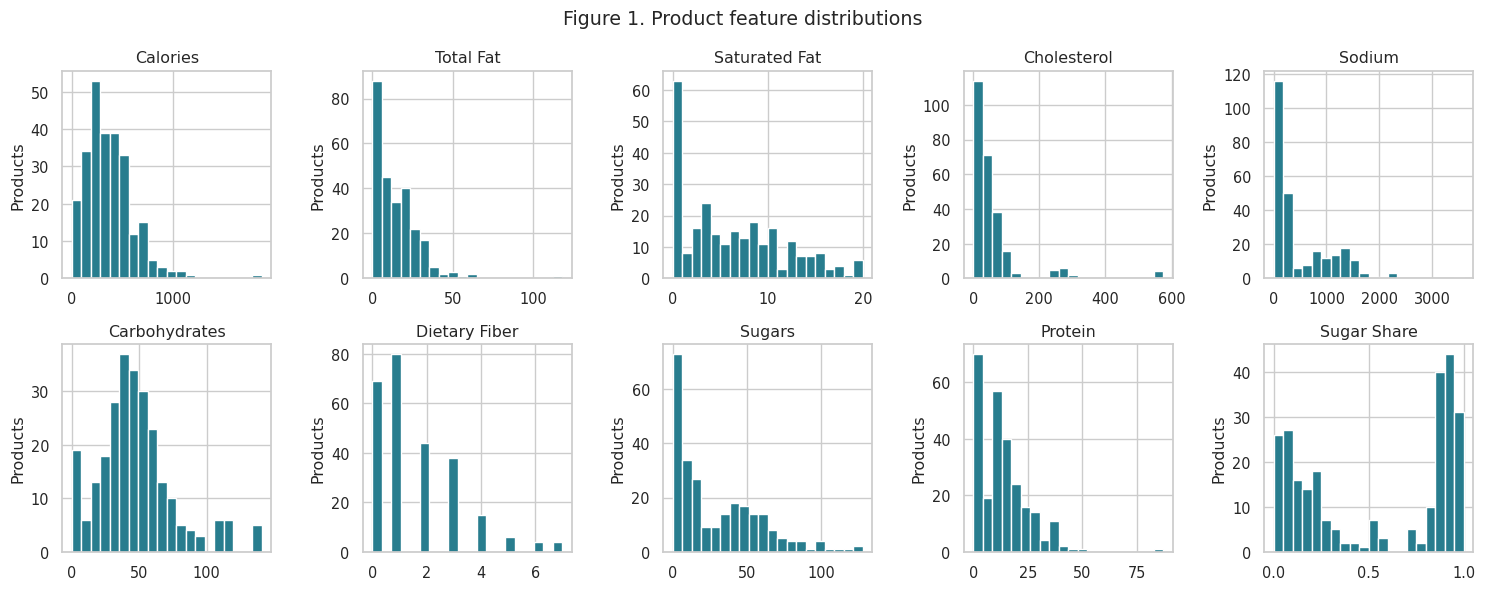

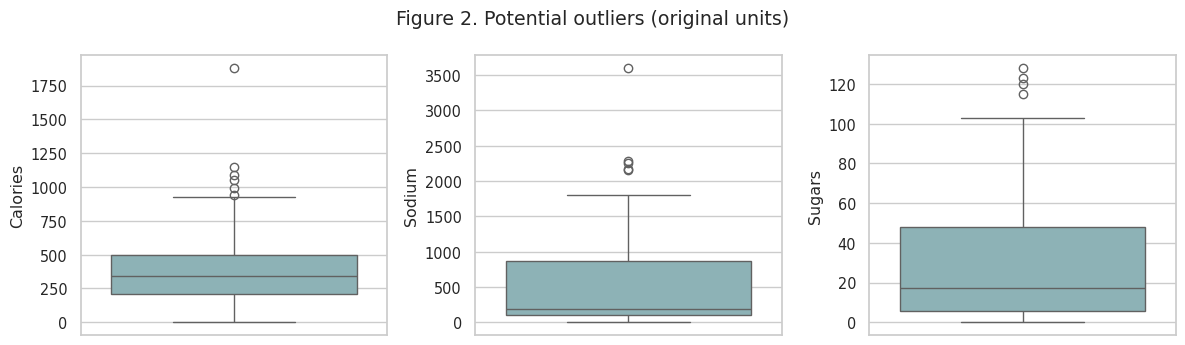

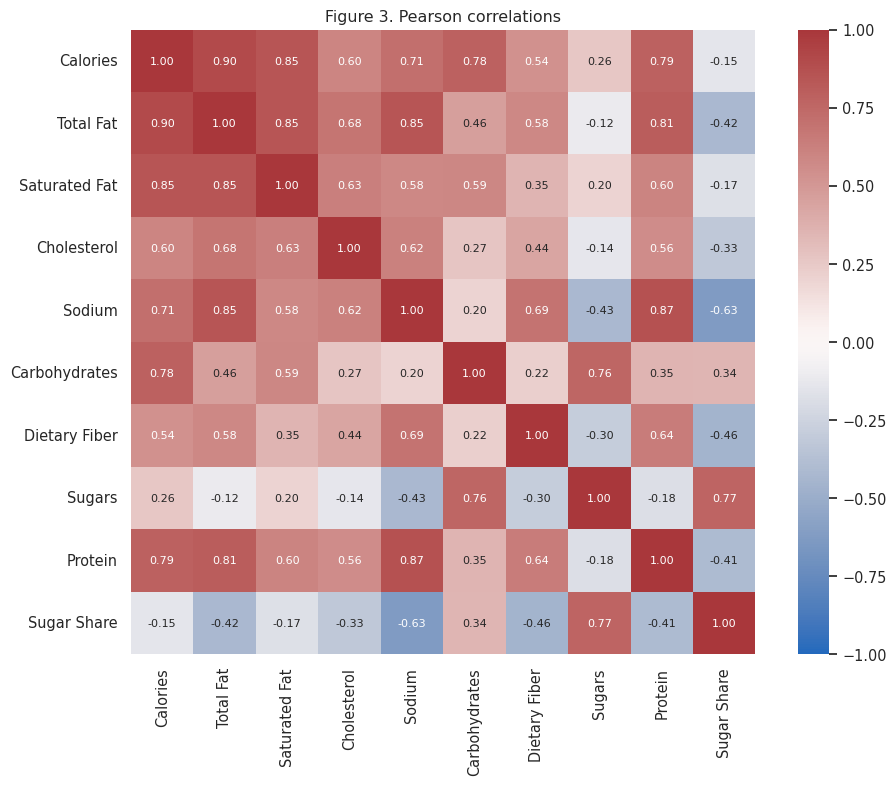

In [ ]:
# EDA figure 1: distributions, with each feature in its own units
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for feature, ax in zip(features, axes.flat):
    ax.hist(X[feature], bins=20, color="#287D8E", edgecolor="white")
    ax.set_title(feature)
    ax.set_ylabel("Products")
fig.suptitle("Figure 1. Product feature distributions")
plt.tight_layout()
plt.show()

# EDA figure 2: potential outliers in three key measurements
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for feature, ax in zip(["Calories", "Sodium", "Sugars"], axes):
    sns.boxplot(y=df[feature], ax=ax, color="#86B8BD")
fig.suptitle("Figure 2. Potential outliers (original units)")
plt.tight_layout()
plt.show()

# EDA figure 3: correlations between the model features
plt.figure(figsize=(10, 8))
sns.heatmap(X.corr(), annot=True, fmt=".2f", cmap="vlag", center=0,
            vmin=-1, vmax=1, square=True, annot_kws={"size": 8})
plt.title("Figure 3. Pearson correlations")
plt.tight_layout()
plt.show()

## 5. Preprocessing
Standardization subtracts each feature's mean and divides by its standard deviation, producing roughly zero mean and unit standard deviation. StandardScaler prevents sodium measured in milligrams from dominating sugar measured in grams simply because its numbers are larger.

K-Means uses Euclidean distance, the straight-line distance between feature vectors. PCA is also affected by scale. We fit the scaler on these products because this task describes the supplied catalog; no future prediction or test-set accuracy is claimed.

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Standardized table shape:", X_scaled.shape)

Standardized table shape: (260, 10)


## 6. Principal component analysis (PCA)


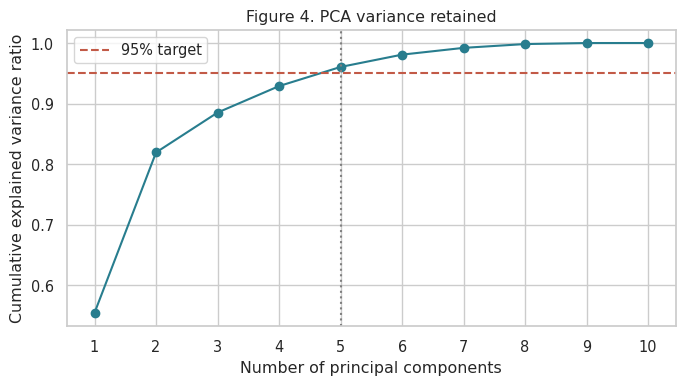

Keep 5 components: 96.05% variance retained.


,PC1 coefficient,PC2 coefficient
Calories,0.387,0.234
Total Fat,0.407,0.017
Saturated Fat,0.347,0.201
Cholesterol,0.316,-0.025
Sodium,0.384,-0.196
Carbohydrates,0.209,0.504
Dietary Fiber,0.300,-0.155
Sugars,-0.051,0.600
Protein,0.376,-0.054
Sugar Share,-0.196,0.474


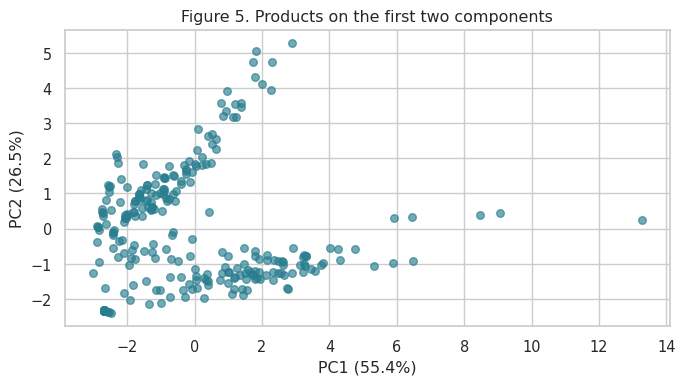

In [ ]:
pca_full = PCA(svd_solver="full").fit(X_scaled)
cumulative = np.cumsum(pca_full.explained_variance_ratio_)
n_components = np.searchsorted(cumulative, 0.95) + 1
pca = PCA(n_components=int(n_components), svd_solver="full")
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(features) + 1), cumulative, "o-", color="#287D8E")
plt.axhline(0.95, color="#C25A47", linestyle="--", label="95% target")
plt.axvline(n_components, color="gray", linestyle=":")
plt.xticks(range(1, len(features) + 1))
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance ratio")
plt.title("Figure 4. PCA variance retained")
plt.legend()
plt.tight_layout()
plt.show()
print(f"Keep {n_components} components: {cumulative[n_components - 1]:.2%} variance retained.")

# These loadings are the coefficients of the standardized features
loadings = pd.DataFrame(pca.components_[:2].T, index=features,
                        columns=["PC1 coefficient", "PC2 coefficient"])
display(loadings.round(3))
plt.figure(figsize=(7, 4))
plt.scatter(X_pca[:, 0], X_pca[:, 1], s=30, alpha=0.65, color="#287D8E")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
plt.title("Figure 5. Products on the first two components")
plt.tight_layout()
plt.show()

**Interpretation.** Five components retain approximately **96.05%** of variance; the first two retain about **81.92%**. **Loadings** here mean the coefficients used to combine standardized features into each PC. Larger absolute coefficients indicate stronger contributions.

PC1 mainly increases with total fat, calories, sodium, and protein, so I interpret it as a substantial savory-meal/portion axis. PC2 increases mainly with sugars, carbohydrates, and Sugar Share, so it separates sweeter carbohydrate-rich products. The signs of PCA axes can reverse without changing their meaning. The 2D view is only a projection; clustering uses all five retained components, not only two.

## 7. Clustering
### 7.1 K-Means: original scaled features versus PCA


,Model,k,Inertia,Silhouette
0,K-Means scaled,2,1670.163,0.386
1,K-Means scaled,3,1228.404,0.373
2,K-Means scaled,4,980.910,0.381
3,K-Means scaled,5,776.546,0.376
4,K-Means scaled,6,669.755,0.357
5,K-Means scaled,7,597.118,0.311
6,K-Means scaled,8,543.318,0.313
7,K-Means PCA,2,1568.571,0.403
8,K-Means PCA,3,1128.649,0.394
9,K-Means PCA,4,883.994,0.407


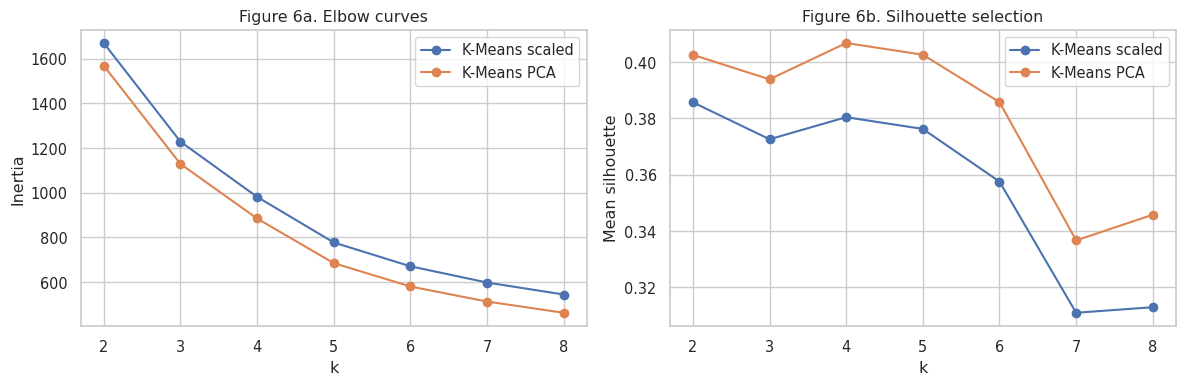

Selected k: {'K-Means scaled': 2, 'K-Means PCA': 4}


In [ ]:
k_values = range(2, 9)
spaces = {"K-Means scaled": X_scaled, "K-Means PCA": X_pca}
km_models = {}
records = []
for name, data in spaces.items():
    for k in k_values:
        model = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
        labels = model.fit_predict(data)
        km_models[(name, k)] = model
        records.append({"Model": name, "k": k, "Inertia": model.inertia_,
                        "Silhouette": silhouette_score(data, labels)})
search = pd.DataFrame(records)
display(search.round(4))

best_k = {}
for name in spaces:
    candidates = search[search["Model"] == name]
    best_k[name] = int(candidates.loc[candidates["Silhouette"].idxmax(), "k"])
km_scaled = km_models[("K-Means scaled", best_k["K-Means scaled"])]
km_pca = km_models[("K-Means PCA", best_k["K-Means PCA"])]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in spaces:
    results = search[search["Model"] == name]
    axes[0].plot(results["k"], results["Inertia"], "o-", label=name)
    axes[1].plot(results["k"], results["Silhouette"], "o-", label=name)
axes[0].set(title="Figure 6a. Elbow curves", xlabel="k", ylabel="Inertia")
axes[1].set(title="Figure 6b. Silhouette selection", xlabel="k", ylabel="Mean silhouette")
for ax in axes:
    ax.set_xticks(list(k_values))
    ax.legend()
plt.tight_layout()
plt.show()
print("Selected k:", best_k)

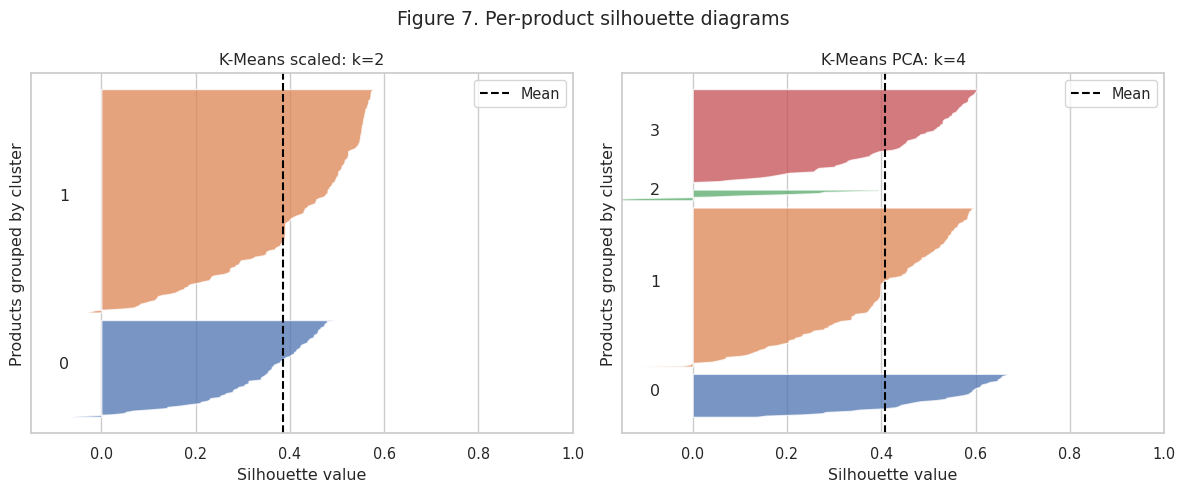

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, data) in zip(axes, spaces.items()):
    model = km_models[(name, best_k[name])]
    values = silhouette_samples(data, model.labels_)
    bottom = 0
    for cluster in range(model.n_clusters):
        cluster_values = np.sort(values[model.labels_ == cluster])
        top = bottom + len(cluster_values)
        ax.fill_betweenx(np.arange(bottom, top), 0, cluster_values, alpha=0.75)
        ax.text(-0.09, (bottom + top) / 2, str(cluster))
        bottom = top + 5
    ax.axvline(values.mean(), color="black", linestyle="--", label="Mean")
    ax.set(title=f"{name}: k={model.n_clusters}", xlabel="Silhouette value",
           ylabel="Products grouped by cluster", xlim=(-0.15, 1))
    ax.set_yticks([])
    ax.legend()
fig.suptitle("Figure 7. Per-product silhouette diagrams")
plt.tight_layout()
plt.show()

### 7.2 Gaussian mixture model (GMM)


,Components,BIC,Converged
0,1,3876.06,True
1,2,3135.88,True
2,3,2572.26,True
3,4,2639.38,True
4,5,2425.01,True
5,6,2306.04,True
6,7,2245.28,True
7,8,2121.61,True


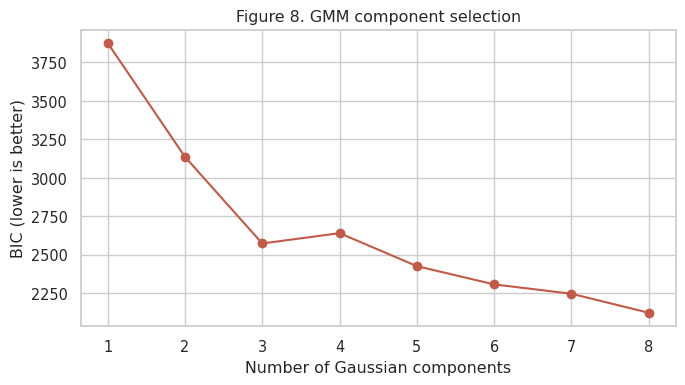

Selected GMM components: 8
The best BIC is at the search boundary; more components might lower BIC further.


In [ ]:
gmm_models = {}
gmm_records = []
for k in range(1, 9):
    model = GaussianMixture(n_components=k, covariance_type="full", n_init=10,
                            reg_covar=1e-5, max_iter=500, random_state=42)
    model.fit(X_pca)
    gmm_models[k] = model
    gmm_records.append({"Components": k, "BIC": model.bic(X_pca),
                        "Converged": model.converged_})
gmm_search = pd.DataFrame(gmm_records)
display(gmm_search.round(2))
gmm_k = int(gmm_search.loc[gmm_search["BIC"].idxmin(), "Components"])
gmm = gmm_models[gmm_k]
gmm_labels = gmm.predict(X_pca)

plt.figure(figsize=(7, 4))
plt.plot(gmm_search["Components"], gmm_search["BIC"], "o-", color="#C25A47")
plt.xlabel("Number of Gaussian components")
plt.ylabel("BIC (lower is better)")
plt.title("Figure 8. GMM component selection")
plt.xticks(range(1, 9))
plt.tight_layout()
plt.show()
print("Selected GMM components:", gmm_k)
if gmm_k == 8:
    print("The best BIC is at the search boundary; more components might lower BIC further.")

## 8. Evaluation and product segments


,Clusters,Silhouette (training),Silhouette (common),Inertia,BIC
Model,,,,,
K-Means scaled,2,0.386,0.386,1670.163,NaN
K-Means PCA,4,0.407,0.384,883.994,NaN
GMM PCA,8,0.252,0.239,NaN,2121.612


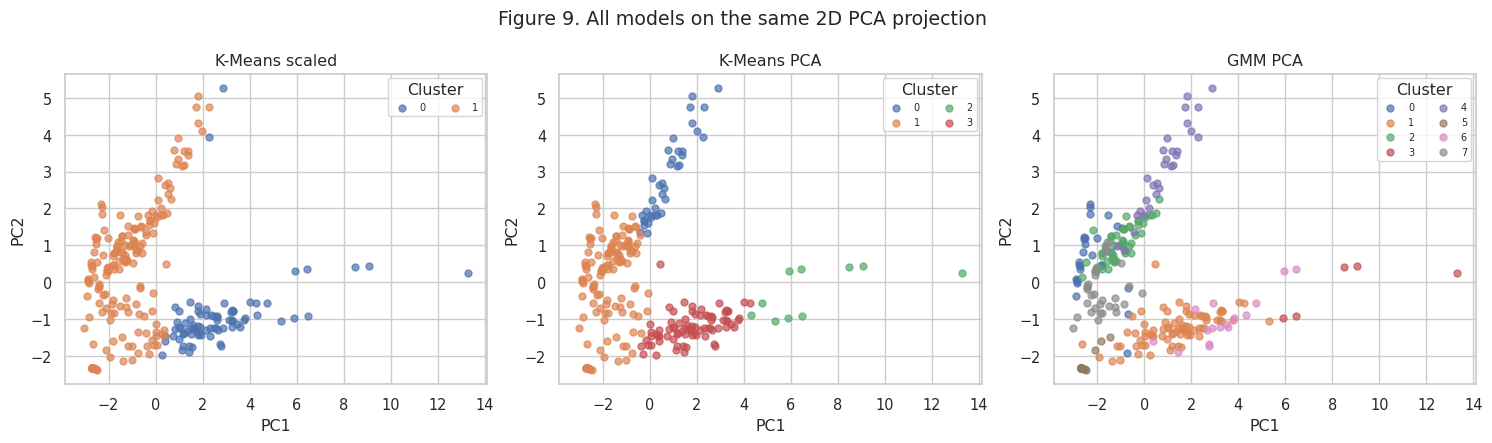

PCA K-Means,0,1,2,3
Scaled K-Means,,,,
0,2,0,10,67
1,35,134,0,12


In [ ]:
labels_by_model = {"K-Means scaled": km_scaled.labels_,
                   "K-Means PCA": km_pca.labels_, "GMM PCA": gmm_labels}
comparison_rows = []
for name, labels in labels_by_model.items():
    data = X_scaled if name == "K-Means scaled" else X_pca
    valid = 1 < len(np.unique(labels)) < len(labels)
    comparison_rows.append({
        "Model": name, "Clusters": len(np.unique(labels)),
        "Silhouette (training)": silhouette_score(data, labels) if valid else np.nan,
        "Silhouette (common)": silhouette_score(X_scaled, labels) if valid else np.nan,
        "Inertia": (km_scaled.inertia_ if name == "K-Means scaled" else
                    km_pca.inertia_ if name == "K-Means PCA" else np.nan),
        "BIC": gmm.bic(X_pca) if name == "GMM PCA" else np.nan
    })
comparison = pd.DataFrame(comparison_rows).set_index("Model")
display(comparison.round(4))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, labels) in zip(axes, labels_by_model.items()):
    for cluster in np.unique(labels):
        mask = labels == cluster
        ax.scatter(X_pca[mask, 0], X_pca[mask, 1], s=25, alpha=0.7, label=str(cluster))
    ax.set(title=name, xlabel="PC1", ylabel="PC2")
    ax.legend(title="Cluster", fontsize=7, ncol=2)
fig.suptitle("Figure 9. All models on the same 2D PCA projection")
plt.tight_layout()
plt.show()

display(pd.crosstab(pd.Series(km_scaled.labels_, name="Scaled K-Means"),
                    pd.Series(km_pca.labels_, name="PCA K-Means")))

Did PCA change the result? Yes. Silhouette selection gives two clusters in the original space and four clusters after PCA. The cross-tabulation above counts products shared by each pair of clusters; numeric cluster IDs are arbitrary. Training-space silhouettes are approximately 0.386 and 0.407, respectively. In the common original space, the PCA grouping scores about 0.384, almost the same as the original grouping. Thus, PCA does not demonstrate a clear improvement in original-space separation.

Recommendation: use K-Means on PCA for menu segmentation because its four groups give more specific business profiles while maintaining similar common-space separation. This is an interpretability decision, not a claim that it wins every metric. The eight-component GMM has lower common-space silhouette (about 0.239); it remains useful for density-based anomaly analysis. BIC prefers eight only within the tested range.

### Segment profiles and business names
A segment profile is the average of each original measurement within a cluster. The names below describe observed nutrition, not proven customer preferences or health recommendations. The naming rules use the observed profile ordering rather than relying on arbitrary cluster IDs.

In [ ]:
df["Cluster"] = km_pca.labels_
profiles = df.groupby("Cluster")[features].mean()
counts = df.groupby("Cluster").size().rename("Products")

# Name the four observed profiles by their defining average measurements
large_id = profiles["Calories"].idxmax()
remaining = profiles.drop(index=large_id)
sweet_id = remaining["Sugars"].idxmax()
remaining = remaining.drop(index=sweet_id)
savory_id = remaining["Sodium"].idxmax()
light_id = remaining.drop(index=savory_id).index[0]
segment_names = {large_id: "Large hearty meals", sweet_id: "Sweet indulgences",
                 savory_id: "Savory staples", light_id: "Lighter mixed items"}
decisions = {
    "Large hearty meals": "Offer smaller-portion alternatives alongside large meals.",
    "Sweet indulgences": "Test small-size dessert or sweet-drink promotions.",
    "Savory staples": "Organize a core savory-meal menu section.",
    "Lighter mixed items": "Create a lower-energy menu section; distinguish drinks from food."
}
profile_table = profiles.copy()
profile_table.insert(0, "Segment", profile_table.index.map(segment_names))
profile_table.insert(1, "Products", counts)
display(profile_table[["Segment", "Products", "Calories", "Total Fat", "Sodium",
                       "Sugars", "Protein", "Sugar Share"]].round(2))
display(pd.DataFrame({"Segment": list(decisions), "Proposed decision": list(decisions.values())}))

for cluster, name in segment_names.items():
    print(f"{name}: " + "; ".join(df.loc[df["Cluster"] == cluster, "Item"].head(3)))

,Segment,Products,Calories,Total Fat,Sodium,Sugars,Protein,Sugar Share
Cluster,,,,,,,,
0,Sweet indulgences,37,593.78,20.27,219.59,78.41,13.43,0.88
1,Lighter mixed items,134,201.87,4.07,114.93,30.54,5.91,0.70
2,Large hearty meals,10,1006.00,56.70,2030.00,9.30,41.00,0.11
3,Savory staples,79,464.18,23.05,1076.84,7.13,22.39,0.16


,Segment,Proposed decision
0,Large hearty meals,Offer smaller-portion alternatives alongside l...
1,Sweet indulgences,Test small-size dessert or sweet-drink promoti...
2,Savory staples,Organize a core savory-meal menu section.
3,Lighter mixed items,Create a lower-energy menu section; distinguis...


Large hearty meals: Steak, Egg & Cheese Bagel; Big Breakfast (Regular Biscuit); Big Breakfast (Large Biscuit)
Sweet indulgences: Caramel Latte (Large); Hazelnut Latte (Large); French Vanilla Latte (Large)
Savory staples: Egg McMuffin; Egg White Delight; Sausage McMuffin
Lighter mixed items: Hotcakes; Hash Brown; Fruit & Maple Oatmeal


The four groups contain **10 large hearty meals**, **37 sweet indulgences**, **79 savory staples**, and **134 lighter mixed items**. Large hearty meals average about 1,006 kcal and 2,030 mg sodium. Sweet indulgences average about 78 g sugar. Savory staples combine moderate-to-high sodium and protein with relatively little sugar. Lighter mixed items average about 202 kcal but still contain diverse products and can have substantial sugar: “lighter” means lower average energy, not universally healthy.

### Lowest-density products: approximately 4%
Probability density measures how concentrated observations are around a point; it is not the probability of that exact product. GMM's `score_samples` returns the logarithm of estimated density. Lower values identify less typical combinations of features.

An anomaly here is a product with unusually low fitted density, not necessarily a data error. I flag exactly `ceil(0.04 × n)` products, rounding up to the next integer: 11 of 260 (4.23%). This is a chosen review quota, not an independently discovered anomaly rate. It uses the fitted GMM even though K-Means is recommended for segmentation.

In [ ]:
df["Log density"] = gmm.score_samples(X_pca)
n_anomalies = int(np.ceil(0.04 * len(df)))
anomaly_index = df["Log density"].nsmallest(n_anomalies).index
df["Anomaly"] = df.index.isin(anomaly_index)
display(df.loc[anomaly_index, ["Item", "Calories", "Sodium", "Dietary Fiber",
                              "Sugars", "Protein", "Log density"]].round(2))
print(f"Flagged {n_anomalies}/{len(df)} products ({df['Anomaly'].mean():.2%}).")

,Item,Calories,Sodium,Dietary Fiber,Sugars,Protein,Log density
39,Cinnamon Melts,460,370,3,32,6,-16.70
89,Premium Southwest Salad with Grilled Chicken,290,680,7,10,27,-13.37
135,Minute Maid Orange Juice (Large),280,5,0,58,4,-11.54
37,Sausage Burrito,300,790,1,2,12,-10.72
47,Double Quarter Pounder with Cheese,750,1280,3,10,48,-9.64
88,Premium Southwest Salad with Crispy Chicken,450,850,7,12,23,-9.59
34,Big Breakfast with Hotcakes and Egg Whites (La...,1050,2290,7,18,35,-9.02
98,Large French Fries,510,290,5,0,6,-8.99
258,McFlurry with Reese's Peanut Butter Cups (Medium),810,400,2,103,21,-8.98
19,"Bacon, Egg & Cheese McGriddles",460,1250,2,15,19,-8.69


Flagged 11/260 products (4.23%).


**Anomaly interpretation.** The flagged products include Cinnamon Melts, Southwest salads, large orange juice, and some substantial breakfasts. They are unusual for different combinations of nutrients: salads have relatively high fiber, orange juice combines sugar with very little fat/sodium, and some breakfasts combine high cholesterol or sodium with particular protein levels. A product does not need the largest calorie value to have low GMM density. Conversely, a tight GMM component can explain an extreme product well, so low-density flags and boxplot outliers need not match. These are review candidates; they are not deleted or described as unsafe foods.

## 9. Conclusion
I segmented 260 real menu products using 10 features, including one engineered sugar-share feature. PCA reduced these to five components, retaining 96.05% of variance. I recommend the four-segment PCA K-Means model: large hearty meals, sweet indulgences, savory staples, and lighter mixed items.

The common-space silhouette is about 0.384, exceeding the predeclared 0.35 target. The profile means support useful descriptive names, so the numerical and basic interpretability criteria are met, although overlap remains and business usefulness still needs stakeholder validation. The GMM flagged 11 products for review.

Limitations
1. This is a small historical US menu snapshot. Serving size affects the nutrient totals, and nutrition alone cannot measure popularity, margins, or demand.
2. Results depend on feature choices, initialization, and the tested cluster range. The best GMM BIC lies at the upper boundary, and the broad lighter-items group is heterogeneous.

Two next steps
1. Add current prices, sales, and serving-mass data, then review segment decisions with menu planners.
2. Test stability across random seeds and updated samples, and extend the GMM component range. Stability means that the main groupings remain similar when reasonable analysis choices or observations change.

## 10. References
1. Kaggle. *Nutrition Facts for McDonald's Menu*. Dataset and download: https://www.kaggle.com/datasets/mcdonalds/nutrition-facts . The dataset credits McDonald's website as the original source. Historical data; accessed 14 October 2026.
2. scikit-learn. *StandardScaler*. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html
3. scikit-learn. *PCA*. https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html
4. scikit-learn. *silhouette_score*. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html
5. scikit-learn. *KMeans*. https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html
6. scikit-learn. *GaussianMixture*. https://scikit-learn.org/stable/modules/generated/sklearn.mixture.GaussianMixture.html
7. scikit-learn. *Gaussian Mixture Model Selection*. https://scikit-learn.org/stable/auto_examples/mixture/plot_gmm_selection.html
